# Fine-tuning the agent: QLoRA on tool-use traces

The untuned agent (`mini_agent`) called its tools correctly, then restated the whole table instead of answering, and
ran out of tokens. Its recall is not the problem: the Qwen3 recall test scored 100% at that context length. The
problem is behaviour, and behaviour is what fine-tuning changes. This notebook teaches Qwen3-1.7B one habit: find the
file, read it, then answer in one sentence with the number and the file it came from.

| Step | What happens | Why |
|---|---|---|
| Baseline | run the untuned model on held-out tasks and score it | without a number from before, there is no way to tell whether training helped |
| Data | generate synthetic labs: random results tables in random folders, questions computed from the tables, and the ideal trace for each (list → read → answer) | the right answer is known exactly; random names and numbers teach the skill, not the answers |
| Masking | train only on the model's own turns, not on the question or the tool results | those are given to the model, not written by it; training on them would teach it to invent tool output |
| QLoRA | base weights frozen in 4-bit; small trainable LoRA matrices (rank 16) added to every attention and MLP projection | about 1% of the weights train, so it fits on one T4 or L4 |
| Eval | the same tasks with the trained adapter, plus questions about your real lab files | the real files were never in training, so they test whether the habit transfers |

**Version 2.** The first run (v1) doubled accuracy on synthetic tasks (35% → 70%) but fell from 17% to 0% on the real
files: every synthetic folder held exactly one table, so the model learned "list, read the only file, answer" and,
faced with a real folder of per-run JSON files, read the wrong one or none and put file sizes in its answers. It also
picked wrong maxima, comparing a dozen numbers by eye. v2 changes the data and the tools, not the training:
- **Decoys.** Each table folder also holds per-run JSON files full of numbers, plots and sometimes a second CSV, as in
  the real lab. The model has to pick the table from the listing.
- **Recovery.** Some traces open a JSON file first, find it lacks the column, then open the table. The wrong step is
  context only, never a training target: the model learns to recover, not to make the mistake.
- **A sort tool.** `sort_table(path, column)` returns the column in order, so a highest/lowest question becomes
  copying the first row. Agents hand arithmetic to tools; the model only has to choose the call.
- **Shorter training.** v1's loss flattened by step 40 of 220; v2 trains about 100 larger steps.

**Version 3.** v2 rose to 80% synthetic and back to 25% real, but only matched the untuned model, which scored 25%
with sort_table in its prompt: the tool helped more than the training. v2's real-file failures had three causes:
- **The wrong folder.** All five "training results" questions without a path went to `recall/`. In v2's labs every
  topic had its own word matching its folder; in the real lab both topics end in "results". v3 makes 40% of labs like
  that: topics share a word ("ablation metrics", "probe metrics"), one table sits in a folder named after the shared
  word, and sometimes every table is called `summary.csv`.
- **Misread cells.** In the right file it still quoted the wrong number, often from a neighbouring column: the recall
  table has 14 columns named like "1 fact @32" and "4 facts @32". v3 adds `get_value(path, run, column)`, and lookups,
  comparisons and missing runs use it; no trace reads a table any more. Some synthetic tables get look-alike columns.
- **Questions that name the file.** All four synthetic failures named the path, took one step, and quoted numbers
  from the table's raw rows, not the sorted list: most likely it read the file instead of sorting. v2 never saved the
  calls, so this is an inference. v3 saves every call with each eval answer, and max questions use more wordings
  ("largest", "minimum").
The real-file questions are the same as in v1 and v2, so those rows compare directly across all versions.

**On Colab:** Runtime → Change runtime type → **L4** → Run all, about 1 hour in total. A T4 also works, in fp16, more
slowly. Results go to `MyDrive/agent-lab/finetune_v3/`; finished steps are skipped when you run it again.

In [1]:
# Config.
import os, sys
IN_COLAB = 'google.colab' in sys.modules
MODEL = os.environ.get('MODEL', 'Qwen/Qwen3-1.7B')
LAB = os.environ.get('AGENT_ROOT', '/content/drive/MyDrive/gpt2-lab' if IN_COLAB else '.')     # real files, for the final eval
OUT = os.environ.get('AGENT_OUT', '/content/drive/MyDrive/agent-lab' if IN_COLAB else 'out')
WORK = '/content/synth' if IN_COLAB else os.path.abspath('synth')                            # synthetic labs, rebuilt each run
VERSION = 'v3'           # results go to OUT/finetune_<VERSION>
N_TRAIN = 400            # training tasks; each gives one example per model turn (about 3.5)
N_EVAL = 20              # held-out synthetic tasks; the real-file tasks come on top
LORA_R, LORA_ALPHA = 16, 32
LR, EPOCHS, ACCUM = 2e-4, 1, 16  # ACCUM examples per optimizer step
MAX_LEN = 3072           # longer examples are skipped
MAX_STEPS = 6            # agent replies allowed per eval task
MAX_NEW_TOKENS = 384     # per reply in the eval: a right answer is one or two sentences
SEED = 2026

In [2]:
# Setup.
import subprocess, csv, json, math, random, re, time
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'bitsandbytes', 'peft'], check=True)
    from google.colab import drive
    drive.mount('/content/drive')
import torch
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, PeftModel, get_peft_model

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
SMOKE = dev == 'cpu'     # no GPU: a tiny random model and a few tasks, to check the code end to end
if SMOKE:
    N_TRAIN, N_EVAL, MAX_NEW_TOKENS, ACCUM = 3, 2, 12, 2
BF16 = dev == 'cuda' and torch.cuda.is_bf16_supported()
compute = torch.bfloat16 if BF16 or SMOKE else torch.float16
FT = f'{OUT}/finetune_{VERSION}' + ('_smoke' if SMOKE else '')
os.makedirs(FT, exist_ok=True)
print(f'{dev} · {torch.cuda.get_device_name() if dev == "cuda" else "CPU smoke test"} · compute {compute}')

Mounted at /content/drive
cuda · NVIDIA L4 · compute torch.bfloat16


## The agent core: tools, tool-call parsing and the loop
Shared by `mini_agent` and `agent_finetune` (build_notebooks.py pastes this file into both), so the fine-tuned model
is trained on exactly the prompt it will see when used.

In [3]:
# Tools. Plain Python functions. The type hints and the docstring are not decoration: transformers turns them into the
# JSON schema that goes into the prompt, and that schema is all the model knows about each tool.
import os, re, json

ROOT = os.path.realpath('.')
READ_LIMIT = 4000        # characters a single read_file returns: every result stays in the context for good

def set_root(path):
    """Point the tools at a folder. They cannot see anything outside it."""
    global ROOT
    ROOT = os.path.realpath(path)

def safe_path(path: str) -> str:
    """Keep every tool inside ROOT, so the model can't read anything else on the machine."""
    full = os.path.realpath(os.path.join(ROOT, path))
    if os.path.commonpath([full, ROOT]) != ROOT:
        raise ValueError(f'{path} is outside the allowed folder')
    return full

def list_files(folder: str = '.') -> str:
    """
    List the files and subfolders in a folder, with file sizes.

    Args:
        folder: Path relative to the lab folder, for example "." or "recall".
    """
    full = safe_path(folder)
    out = []
    for name in sorted(os.listdir(full)):
        p = os.path.join(full, name)
        out.append(f'{name}/' if os.path.isdir(p) else f'{name}  ({os.path.getsize(p):,} bytes)')
    return '\n'.join(out) or '(empty folder)'

def read_file(path: str) -> str:
    """
    Read a text file (csv, json, md, txt, py). Long files are cut off.

    Args:
        path: Path relative to the lab folder, for example "recall/summary.csv".
    """
    text = open(safe_path(path), encoding='utf-8', errors='replace').read()
    return text if len(text) <= READ_LIMIT else text[:READ_LIMIT] + f'\n... [cut: {len(text):,} characters in total]'

def load_table(path, column):
    """A CSV's rows, the column that names each row (run, name or model), and an error message for the model if the
    file or the column is not usable. Not a tool: the tools below share it."""
    import csv
    if not path.lower().endswith('.csv'):
        return None, None, f'Error: {path} is not a .csv table'
    with open(safe_path(path), encoding='utf-8', errors='replace', newline='') as f:
        rows = list(csv.DictReader(f))
    if not rows:
        return None, None, f'Error: {path} has no rows'
    header = list(rows[0])
    if column not in header:
        return None, None, f'Error: there is no column {column!r} in {path}. Columns: {", ".join(header)}'
    return rows, next((h for h in ('run', 'name', 'model') if h in header), header[0]), None

def get_value(path: str, run: str, column: str) -> str:
    """
    Look up one value in a CSV table: the cell in a run's row and a column. Use it instead of reading the table, so
    the number cannot come from the wrong row or column.

    Args:
        path: Path to a .csv file relative to the lab folder, for example "results/summary.csv".
        run: The run's name, written exactly as in the table's first column.
        column: The column, written exactly as in the table's header.
    """
    rows, key, err = load_table(path, column)
    if err:
        return err
    hit = [r for r in rows if r[key] == run] or [r for r in rows if r[key].lower() == run.strip().lower()]
    if not hit:
        return f'Error: there is no run named {run!r} in {path}. Runs: {", ".join(r[key] for r in rows)}'
    v = hit[0][column]
    return f'{path}: {hit[0][key]} has {column} = {v}' if v.strip() else f'{path}: {hit[0][key]} has no {column} value (blank)'

def sort_table(path: str, column: str, descending: bool = True) -> str:
    """
    Sort a CSV table by one numeric column and list every run with its value, in order. Use it to find the highest or
    lowest value instead of comparing numbers by eye.

    Args:
        path: Path to a .csv file relative to the lab folder, for example "results/summary.csv".
        column: The column to sort by, written exactly as in the table's header.
        descending: true lists the highest value first, false the lowest first.
    """
    if isinstance(descending, str):
        descending = descending.strip().lower() not in ('false', '0', 'no')
    rows, key, err = load_table(path, column)
    if err:
        return err
    def value(r):
        try:
            return float(r[column])
        except (TypeError, ValueError):
            return None
    have = sorted((r for r in rows if value(r) is not None), key=value, reverse=descending)
    blank = len(rows) - len(have)
    return (f'{path} sorted by {column}, {"highest" if descending else "lowest"} first '
            f'({len(have)} rows{f", {blank} blank" if blank else ""}):\n{key},{column}\n'
            + '\n'.join(f'{r[key]},{r[column]}' for r in have))

TOOLS = {f.__name__: f for f in (list_files, read_file, get_value, sort_table)}

def run_tool(name, args):
    """Run one tool call. Errors go back to the model as text, so it can correct itself instead of crashing the loop."""
    if name not in TOOLS:
        return f'Error: there is no tool named {name}. Available: {", ".join(TOOLS)}'
    try:
        return TOOLS[name](**args)
    except (FileNotFoundError, NotADirectoryError):
        where = args.get('path', args.get('folder', ''))
        return f'Error: there is no file or folder {where!r}. List the folder above it to see what is there.'
    except Exception as e:
        return f'Error: {type(e).__name__}: {e}'

In [4]:
# The model's side of tool calling. Qwen3 was trained to answer a tool request in one fixed format:
#   <tool_call>
#   {"name": "read_file", "arguments": {"path": "recall/summary.csv"}}
#   </tool_call>
# The chat template writes the tool schemas into the prompt; parse_tool_calls reads that format back out.
TOOL_CALL = re.compile(r'<tool_call>\s*(\{.*?\})\s*</tool_call>', re.S)

def parse_tool_calls(text):
    calls = []
    for m in TOOL_CALL.finditer(text):
        try:
            c = json.loads(m.group(1))
            calls.append(dict(name=c['name'], arguments=c.get('arguments', {})))
        except (json.JSONDecodeError, KeyError, TypeError) as e:
            calls.append(dict(name='invalid', arguments={}, error=f'Error: could not parse {m.group(1)!r}: {e}'))
    return calls

def assistant_turn(reply, calls):
    """The message stored for a reply that called tools. The chat template writes each call from `tool_calls`, so the
    <tool_call> text comes out of `content`: left in, every call would appear twice in the history."""
    return dict(role='assistant', content=TOOL_CALL.sub('', reply).strip(),
                tool_calls=[dict(type='function', function=dict(name=c['name'], arguments=c['arguments'])) for c in calls])

In [5]:
# The loop. This is the whole agent. `generate(messages)` returns (reply, prompt length in tokens).
SYSTEM = ('You are a research assistant for a lab that trains small language models and benchmarks them. '
          'Answer from the files, not from memory: list folders to find files, read them, then answer. '
          'For one value in a table, use get_value; for the highest or lowest (best, worst, fastest, largest), use '
          'sort_table. Do not read numbers off a table yourself. '
          'Quote the numbers you use and name the file they came from.')

def run_agent(task, generate, max_steps=8, verbose=True):
    messages = [dict(role='system', content=SYSTEM), dict(role='user', content=task)]
    n_calls = bad_calls = 0
    for step in range(1, max_steps + 1):
        reply, ctx = generate(messages)
        calls = parse_tool_calls(reply)
        if verbose:
            print(f'\n── step {step} · context {ctx:,} tokens ──\n{reply.strip()}')
        if not calls:                                         # no tool requested: this is the final answer
            return dict(answer=reply.strip(), steps=step, calls=n_calls, bad_calls=bad_calls, context=ctx, messages=messages)
        messages.append(assistant_turn(reply, calls))
        for c in calls:
            result = c['error'] if 'error' in c else run_tool(c['name'], c['arguments'])
            n_calls += 1
            bad_calls += result.startswith('Error')
            if verbose:
                print(f'  → {c["name"]}({json.dumps(c["arguments"])}) returned {len(result):,} characters')
            messages.append(dict(role='tool', name=c['name'], content=result))
    return dict(answer=None, steps=max_steps, calls=n_calls, bad_calls=bad_calls, context=ctx, messages=messages)

## Synthetic labs
Each lab is a small folder like your Drive one: two or three results tables in subfolders, plus a README, notes and
run files to ignore. Run names, metrics and numbers are random. Folder names never include `results` or `recall`, so
the real-file eval is a fair test of transfer.

In [6]:
NAME_A = 'alpha beta gamma delta sigma omega tiny small wide deep fast lite base mini dense sparse long flat swift core'.split()
NAME_B = 'net former mix glu norm rope attn conv moe mqa gqa hybrid relu gelu v2 v3 xl kv'.split()
METRICS = [('val loss', 2.5, 4.5, 4), ('train loss', 2.0, 4.0, 4), ('perplexity', 10, 90, 1), ('accuracy %', 20, 95, 1),
           ('F1 %', 20, 95, 1), ('BLEU', 5, 45, 1), ('exact match %', 5, 80, 1), ('recall @1K %', 0, 100, 1),
           ('copy score %', 0, 100, 1), ('tok/s (k)', 20, 250, 0), ('latency ms', 3, 250, 1), ('memory GiB', 0.5, 40, 2),
           ('params (M)', 10, 900, 1), ('MFU %', 5, 60, 0), ('train min', 5, 300, 1), ('KV KiB/token', 1, 64, 1),
           ('score', 0, 1, 3), ('win rate %', 0, 100, 1), ('steps', 500, 20000, 0), ('grad norm', 0.1, 5, 3)]
CATEGORIES = [('family', ['dense', 'sparse', 'hybrid', 'baseline']), ('budget', ['quick', 'standard', 'long']),
              ('optimizer', ['adamw', 'lion', 'sgd'])]
FAMILIES = [[('acc @1K %', 0, 100, 1), ('acc @4K %', 0, 100, 1), ('acc @16K %', 0, 100, 1)],     # columns whose names
            [('pass@1 %', 0, 100, 1), ('pass@10 %', 0, 100, 1), ('pass@100 %', 0, 100, 1)],  # differ by one token, as in
            [('1-shot %', 0, 100, 1), ('5-shot %', 0, 100, 1), ('25-shot %', 0, 100, 1)],    # the real recall table
            [('top-1 %', 0, 100, 1), ('top-5 %', 0, 100, 1)]]
# (folder, file, topic, qualifier). The qualifier names the table in a lab whose topics share a word (see make_lab).
TABLES = [('eval', 'scores.csv', 'evaluation scores', 'evaluation'), ('benchmarks', 'speed.csv', 'speed benchmarks', 'benchmark'),
          ('ablations', 'table.csv', 'ablation runs', 'ablation'), ('sweeps', 'lr_sweep.csv', 'learning-rate sweep', 'sweep'),
          ('baselines', 'baselines.csv', 'baseline runs', 'baseline'), ('probes', 'probe_results.csv', 'probing results', 'probe'),
          ('finetune', 'metrics.csv', 'fine-tuning metrics', 'fine-tuning'), ('long_context', 'summary.csv', 'long-context tests', 'long-context')]
SHARED = ['metrics', 'scores', 'tables', 'evals', 'stats', 'reports']

def run_names(rng, n):
    names = set()
    while len(names) < n:
        a, b, k = rng.choice(NAME_A), rng.choice(NAME_B), rng.randint(1, 64)
        names.add(rng.choice([f'{a}-{b}', f'{a}+{b}', f'{b}-{k}', f'{a}{k}', f'{a}-{b}-{k}']))
    return sorted(sorted(names), key=lambda _: rng.random())   # sort first: a set's order changes between runs

def fmt(v, d):
    return f'{v:.{d}f}' if d else str(int(round(v)))

def write_decoys(drng, folder, runs, table_file):
    """Files that sit next to a table, as in the real lab: per-run JSON logs full of numbers, a plot, sometimes a second
    CSV of training curves. Returns the JSON names. Uses its own random generator, so the decoys do not change which
    questions get asked."""
    names = []
    for r in drng.sample(runs, drng.randint(4, 14)):
        name = drng.choice([f'{r}.json', f'{r}__standard.json', f'{r}__seed{drng.randint(1, 3)}.json'])
        log = dict(name=r, budget=drng.choice(['quick', 'standard']), steps=drng.randint(500, 5000),
                   final=dict(val_loss=round(drng.uniform(2.5, 4.5), 4), tok_per_s=drng.randint(40000, 250000)),
                   curve=[round(drng.uniform(2.5, 9), 3) for _ in range(drng.randint(10, 40))])
        with open(os.path.join(folder, name), 'w') as f:
            json.dump(log, f)
        names.append(name)
    with open(os.path.join(folder, os.path.splitext(table_file)[0] + '.png'), 'wb') as f:
        f.write(drng.randbytes(drng.randint(20000, 90000)))
    if drng.random() < 0.3:
        with open(os.path.join(folder, 'curves.csv'), 'w') as f:
            f.write('step,loss,lr\n' + ''.join(f'{s},{drng.uniform(2.5, 9):.3f},{1e-3:.0e}\n' for s in range(0, 2000, 100)))
    return sorted(set(names))

def make_lab(rng, root):
    """Write one synthetic lab to `root` and return its tables (folder, file, topic, rows)."""
    os.makedirs(root, exist_ok=True)
    runs = run_names(rng, 18)
    tables = []
    chosen = rng.sample(TABLES, rng.randint(2, 3))
    if rng.random() < 0.4:
        # Topics that share a word, as in the real lab ("training results" in results/, "recall test results" in
        # recall/). The first table's folder is the shared word itself, so its qualifier matches no folder name: the
        # model has to rule out the folders that do match the other topics.
        word, same_file = rng.choice(SHARED), rng.random() < 0.5
        chosen = [(word if i == 0 else folder, 'summary.csv' if same_file else file, f'{qual} {word}')
                  for i, (folder, file, _, qual) in enumerate(chosen)]
    else:
        chosen = [(folder, file, topic) for folder, file, topic, _ in chosen]
    for folder, file, topic in chosen:
        while True:
            rows_runs = rng.sample(runs, rng.randint(5, 16))
            metrics = rng.sample(METRICS, rng.randint(3, 10))
            if rng.random() < 0.3:
                metrics += rng.choice(FAMILIES)
            cats = rng.sample(CATEGORIES, rng.randint(0, 1))
            header = ['run'] + [c for c, _ in cats] + [m[0] for m in metrics]
            rows = []
            for r in rows_runs:
                row = {'run': r, **{c: rng.choice(v) for c, v in cats}}
                for name, lo, hi, d in metrics:
                    row[name] = '' if rng.random() < 0.04 else fmt(rng.uniform(lo, hi), d)
                rows.append(row)
            buf = [','.join(header)] + [','.join(row[h] for h in header) for row in rows]
            if len('\n'.join(buf)) < READ_LIMIT - 200:
                break
        os.makedirs(os.path.join(root, folder), exist_ok=True)
        with open(os.path.join(root, folder, file), 'w', newline='', encoding='utf-8') as f:
            w = csv.DictWriter(f, header)
            w.writeheader()
            w.writerows(rows)
        decoys = write_decoys(random.Random(f'{root}/{folder}'), os.path.join(root, folder), runs, file)
        tables.append(dict(root=root, folder=folder, file=file, topic=topic, rows=rows, decoys=decoys,
                           numeric=[m[0] for m in metrics], decimals={m[0]: m[3] for m in metrics}))
    with open(os.path.join(root, 'README.md'), 'w') as f:
        f.write('# Lab\n\nTraining and evaluation runs. Tables are in the subfolders; run logs are in runs/.\n')
    with open(os.path.join(root, 'notes.txt'), 'w') as f:
        f.write(f'TODO: rerun {rng.choice(runs)} with a second seed.\nCheck the {rng.choice(METRICS)[0]} numbers.\n')
    os.makedirs(os.path.join(root, 'runs'), exist_ok=True)
    for r in rng.sample(runs, 3):
        with open(os.path.join(root, 'runs', f'{r}.json'), 'w') as f:
            json.dump(dict(name=r, seed=rng.randint(0, 9999), lr=rng.choice([3e-4, 6e-4, 1e-3])), f)
    return tables

## Tasks and their ideal traces
A task is a question, the exact strings a right answer must contain (`gold`), and the ideal trace: the replies a good
agent would write, in order. A reply is either one tool call or the final answer, and carries a flag: trained on, or
context only (the wrong first step of a recovery trace).

In [7]:
def num(s):
    return float(s)

def decimals(table, col):
    if col in table.get('decimals', {}):
        return table['decimals'][col]
    vals = [r[col] for r in table['rows'] if r[col]]
    return max((len(v.split('.')[1]) if '.' in v else 0) for v in vals)

def tool_call(name, train=True, **args):
    """A reply that calls one tool, written exactly as Qwen3 writes it."""
    return ('<tool_call>\n' + json.dumps({'name': name, 'arguments': args}, ensure_ascii=False) + '\n</tool_call>',
            [dict(name=name, arguments=args)], train)

HIGH, LOW = ['highest', 'largest', 'maximum'], ['lowest', 'smallest', 'minimum']

def make_task(rng, table, kinds, vary=True):
    """One question about `table`, with gold strings and the ideal trace. Returns None if the table can't support it.
    vary=False keeps the v1/v2 wording (used for the real-file tasks, so they stay the same questions across versions)."""
    rows = table['rows']
    path = f"{table['folder']}/{table['file']}"
    cols = [c for c in table['numeric'] if c in rows[0] and sum(bool(r[c]) for r in rows) >= 4]
    if not cols:
        return None
    col = rng.choice(cols)
    have = [r for r in rows if r[col]]
    kind = rng.choices(*zip(*kinds.items()))[0]
    explicit = rng.random() < 0.3
    where = path if explicit else f'the {table["topic"]}'
    d = decimals(table, col)
    srng = random.Random(f"{table['root']}/{path}/{col}")    # wording only, so `rng` draws stay as in v2
    if kind == 'max':
        word = rng.choice(['highest', 'lowest'])
        ranked = sorted(have, key=lambda r: num(r[col]), reverse=word == 'highest')
        if num(ranked[0][col]) == num(ranked[1][col]):
            return None
        best = ranked[0]
        said = srng.choice(HIGH if word == 'highest' else LOW) if vary else word
        q = rng.choice([f'Which run has the {said} {col} in {where}?', f'In {where}, which run has the {said} {col}?',
                        f'Find the run with the {said} {col} in {where}.'])
        gold = [best['run'], best[col]]
        answer = rng.choice([f'{best["run"]} has the {said} {col}: {best[col]} ({path}).',
                             f'The {said} {col} is {best[col]}, from {best["run"]} ({path}).'])
        calls = [('sort_table', dict(path=path, column=col, descending=word == 'highest'))]
    elif kind == 'lookup':
        r = rng.choice(have)
        q = rng.choice([f"What is {r['run']}'s {col} in {where}?", f'In {where}, what {col} did {r["run"]} get?'])
        gold = [r[col]]
        answer = f"{r['run']} has a {col} of {r[col]} ({path})."
        calls = [('get_value', dict(path=path, run=r['run'], column=col))]
    elif kind == 'compare':
        a, b = rng.sample(have, 2)
        if num(a[col]) == num(b[col]):
            return None
        hi = a if num(a[col]) > num(b[col]) else b
        diff = fmt(abs(num(a[col]) - num(b[col])), d)
        q = rng.choice([f'How does {a["run"]} compare with {b["run"]} on {col} in {where}?',
                        f'In {where}, is {a["run"]} or {b["run"]} higher on {col}?'])
        gold = [a[col], b[col]]
        answer = f'{a["run"]} has a {col} of {a[col]} and {b["run"]} has {b[col]}, so {hi["run"]} is higher by {diff} ({path}).'
        calls = [('get_value', dict(path=path, run=a['run'], column=col)), ('get_value', dict(path=path, run=b['run'], column=col))]
    else:   # 'missing': the run is not in the table; get_value says so and lists the runs, and the answer passes that on
        fake = next(n for n in run_names(rng, 40) if n not in {r['run'] for r in rows})
        q = f"What is {fake}'s {col} in {where}?"
        gold = ['no run']
        answer = f'There is no run named {fake} in {path}. It lists: {", ".join(r["run"] for r in rows)}.'
        calls = [('get_value', dict(path=path, run=fake, column=col))]
    trace = []
    trng = random.Random(q)      # trace choices get their own generator, so they don't change later questions
    if explicit and rng.random() < 0.25 and kind != 'missing':   # a wrong path in the question: recover by listing
        stem, ext = os.path.splitext(table['file'])
        wrong = f"{table['folder']}/{stem.rstrip('s') if stem.endswith('s') else stem + 's'}{ext}"
        q = q.replace(path, wrong)
        name, args = calls[0]
        trace += [tool_call(name, **dict(args, path=wrong)), tool_call('list_files', folder=table['folder'])]
    elif not explicit:
        trace += [tool_call('list_files', folder='.'), tool_call('list_files', folder=table['folder'])]
        if table.get('decoys') and trng.random() < 0.3:   # opens a run log first: context only, never a target
            trace.append(tool_call('read_file', train=False, path=f"{table['folder']}/{trng.choice(table['decoys'])}"))
    # The table itself is never read: every number comes from a tool, so none can come from the wrong row or column.
    trace += [tool_call(name, **args) for name, args in calls]
    trace.append((answer, None, True))
    return dict(root=table['root'], path=path, kind=kind, question=q, gold=gold, trace=trace)

def synthetic_tasks(n, seed, kinds, name):
    rng, tasks = random.Random(seed), []
    while len(tasks) < n:
        lab = make_lab(rng, f'{WORK}/{name}/lab{len(tasks):04d}')
        t = make_task(rng, rng.choice(lab), kinds)
        if t:
            tasks.append(dict(t, set='synthetic'))
    return tasks

TRAIN_KINDS = {'max': 0.35, 'lookup': 0.25, 'compare': 0.3, 'missing': 0.1}
EVAL_KINDS = {'max': 0.4, 'lookup': 0.3, 'compare': 0.3}
train_tasks = synthetic_tasks(N_TRAIN, SEED, TRAIN_KINDS, 'train')
eval_tasks = synthetic_tasks(N_EVAL, SEED + 1, EVAL_KINDS, 'eval')
t = train_tasks[0]
print(f'{len(train_tasks)} training tasks, {len(eval_tasks)} synthetic eval tasks. Example:\n{t["question"]}')
for reply, _, train in t['trace']:
    print('  ' + reply.replace('\n', ' ') + ('' if train else '   (context only)'))

400 training tasks, 20 synthetic eval tasks. Example:
In the ablation runs, what top-1 % did lite-v2 get?
  <tool_call> {"name": "list_files", "arguments": {"folder": "."}} </tool_call>
  <tool_call> {"name": "list_files", "arguments": {"folder": "ablations"}} </tool_call>
  <tool_call> {"name": "get_value", "arguments": {"path": "ablations/table.csv", "run": "lite-v2", "column": "top-1 %"}} </tool_call>
  lite-v2 has a top-1 % of 68.0 (ablations/table.csv).


In [8]:
# Real-file tasks: the same question types about your lab's own tables, with gold answers read from the files.
REAL_TABLES = [('results', 'summary.csv', 'training results', ['val loss', 'HellaSwag %', 'train tok/s (k)', 'KV KiB/token', 'train min']),
               ('recall', 'summary.csv', 'recall test results', ['copy near %', 'copy far %', '1 fact @32', '4 facts @32', '16 facts @32'])]
rng = random.Random(SEED + 2)
real_tasks = []
for folder, file, topic, cols in REAL_TABLES:
    p = os.path.join(LAB, folder, file)
    if not os.path.exists(p):
        print(f'skipped {folder}/{file}: not found in {LAB}')
        continue
    rows = list(csv.DictReader(open(p, encoding='utf-8')))
    table = dict(root=LAB, folder=folder, file=file, topic=topic, rows=rows, numeric=[c for c in cols if c in rows[0]])
    for _ in range(200):
        if sum(t['path'] == f'{folder}/{file}' for t in real_tasks) == 6:
            break
        t = make_task(rng, table, EVAL_KINDS, vary=False)
        if t and t['question'] not in {x['question'] for x in real_tasks}:
            real_tasks.append(dict(t, set='real'))
print(f'{len(real_tasks)} real-file tasks')
for t in real_tasks[:3]:
    print(' ', t['question'], '→', t['gold'])

12 real-file tasks
  In the training results, is attn-swa or gpt2+rmsnorm higher on train tok/s (k)? → ['139.0', '187.0']
  What is attn-swa's HellaSwag % in results/summary.csv? → ['26.0']
  What is gpt2+swiglu's train min in the training results? → ['45.9']


## The model: 4-bit base
NF4 stores each weight in 4 bits, so the 1.7B model takes about 1.2 GB. Matmuls still run in bf16 (fp16 on a T4):
weights are unpacked on the fly. The recall test showed 4-bit loses nothing measurable for this model.

In [9]:
tok = AutoTokenizer.from_pretrained(MODEL)
if SMOKE:
    cfg = AutoConfig.from_pretrained(MODEL)
    cfg.update(dict(hidden_size=64, intermediate_size=128, num_hidden_layers=2, num_attention_heads=4,
                    num_key_value_heads=2, head_dim=16))
    model = AutoModelForCausalLM.from_config(cfg).to(compute)
else:
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=compute,
                             bnb_4bit_use_double_quant=True)
    model = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb, dtype=compute, device_map={'': 0})
model.eval()
print(f'{MODEL}: {torch.cuda.memory_allocated() / 2**30:.2f} GiB on GPU' if dev == 'cuda' else 'tiny random model')

def render(messages):
    return tok.apply_chat_template(messages, tools=list(TOOLS.values()), add_generation_prompt=True,
                                   tokenize=False, enable_thinking=False)

@torch.no_grad()
def generate(messages):
    ids = tok(render(messages), return_tensors='pt', add_special_tokens=False).to(dev)
    out = model.generate(**ids, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, ids['input_ids'].shape[1]:], skip_special_tokens=True), ids['input_ids'].shape[1]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B: 1.26 GiB on GPU


## Scoring
A task is correct when the final answer contains every gold string: the run name and the number, as written in the
file. Matching is exact, so `gpt2` does not count as a mention of `gpt2+rope`, and `3.741` not as `13.7415`.

In [10]:
def mentions(text, s):
    return re.search(r'(?<![\w.+\-])' + re.escape(s) + r'(?![\w+\-]|\.\d)', text, re.I) is not None

def files_read(messages):
    return [c['function']['arguments'].get('path', '').lstrip('./') for m in messages if m['role'] == 'assistant'
            for c in m.get('tool_calls', []) if c['function']['name'] in ('read_file', 'get_value', 'sort_table')]

def trace_of(messages):
    """Every tool call with the start of its result, saved with each eval answer so a wrong answer can be traced to the
    call that caused it (v2 saved only the answers, which left its failures to guesswork)."""
    calls = [dict(name=c['function']['name'], arguments=c['function']['arguments'])
             for m in messages if m['role'] == 'assistant' for c in m.get('tool_calls', [])]
    results = [m['content'][:300] for m in messages if m['role'] == 'tool']
    return [dict(c, result=r) for c, r in zip(calls, results)]

def evaluate(tasks, label):
    path = f'{FT}/eval_{label}.json'
    if os.path.exists(path):
        print(f'{label}: loaded from {path}')
        return json.load(open(path))
    rows, t0 = [], time.time()
    for i, t in enumerate(tasks):
        set_root(t['root'])
        r = run_agent(t['question'], generate, max_steps=MAX_STEPS, verbose=False)
        ans = r['answer'] or ''
        rows.append(dict(set=t['set'], kind=t['kind'], question=t['question'], gold=t['gold'], answer=ans,
                         correct=all(mentions(ans, g) for g in t['gold']), finished=r['answer'] is not None,
                         found=t['path'] in files_read(r['messages']), steps=r['steps'], calls=r['calls'],
                         bad_calls=r['bad_calls'], chars=len(ans), trace=trace_of(r['messages'])))
        print(f'{label} {i + 1}/{len(tasks)} · {"✓" if rows[-1]["correct"] else "✗"} · {r["steps"]} steps · '
              f'{len(ans)} chars · {time.time() - t0:.0f} s')
    json.dump(rows, open(path, 'w'), indent=1)
    return rows

def summary(results):
    print(f'{"model":<8}{"set":<11}{"tasks":>6}{"correct %":>11}{"read the file %":>17}{"finished %":>12}'
          f'{"avg steps":>11}{"avg answer chars":>18}{"bad calls":>11}')
    for label, rows in results.items():
        for s in ('synthetic', 'real'):
            rs = [r for r in rows if r['set'] == s]
            if rs:
                avg = lambda k: sum(r[k] for r in rs) / len(rs)
                print(f'{label:<8}{s:<11}{len(rs):>6}{100 * avg("correct"):>11.0f}{100 * avg("found"):>17.0f}'
                      f'{100 * avg("finished"):>12.0f}{avg("steps"):>11.1f}{avg("chars"):>18.0f}{sum(r["bad_calls"] for r in rs):>11}')

In [11]:
# Baseline: the untuned model on the eval tasks.
results = {'base': evaluate(eval_tasks + real_tasks, 'base')}
summary(results)

base 1/32 · ✓ · 4 steps · 46 chars · 13 s
base 2/32 · ✗ · 6 steps · 0 chars · 24 s
base 3/32 · ✗ · 6 steps · 372 chars · 48 s
base 4/32 · ✗ · 2 steps · 162 chars · 51 s
base 5/32 · ✓ · 2 steps · 163 chars · 56 s
base 6/32 · ✗ · 3 steps · 446 chars · 69 s
base 7/32 · ✓ · 2 steps · 74 chars · 73 s
base 8/32 · ✓ · 4 steps · 154 chars · 83 s
base 9/32 · ✗ · 2 steps · 96 chars · 86 s
base 10/32 · ✗ · 6 steps · 322 chars · 107 s
base 11/32 · ✗ · 6 steps · 0 chars · 128 s
base 12/32 · ✗ · 4 steps · 257 chars · 138 s
base 13/32 · ✓ · 4 steps · 46 chars · 148 s
base 14/32 · ✗ · 4 steps · 97 chars · 161 s
base 15/32 · ✗ · 6 steps · 0 chars · 186 s
base 16/32 · ✗ · 2 steps · 135 chars · 192 s
base 17/32 · ✓ · 2 steps · 46 chars · 195 s
base 18/32 · ✗ · 3 steps · 262 chars · 203 s
base 19/32 · ✓ · 2 steps · 99 chars · 208 s
base 20/32 · ✗ · 6 steps · 0 chars · 229 s
base 21/32 · ✗ · 5 steps · 369 chars · 260 s
base 22/32 · ✓ · 2 steps · 84 chars · 264 s
base 23/32 · ✗ · 3 steps · 187 chars · 270 s

## Training examples and the loss mask
Each training task is replayed exactly as `run_agent` would run it: the tools really run on the synthetic lab, and the
prompt for each turn is built with the same chat template. Every model turn becomes one example: the prompt
(system prompt, tool schemas, question, earlier calls and results) gets label -100, which the loss ignores, and only
the reply the model should write is trained on, ending with `<|im_end|>` so it also learns when to stop.

In [12]:
def turn_examples(task):
    set_root(task['root'])
    messages = [dict(role='system', content=SYSTEM), dict(role='user', content=task['question'])]
    out = []
    for reply, calls, train in task['trace']:
        if train:            # a context-only step (the wrong first read of a recovery trace) is never a target
            p = tok(render(messages), add_special_tokens=False)['input_ids']
            t = tok(reply + '<|im_end|>', add_special_tokens=False)['input_ids']
            out.append(dict(ids=p + t, labels=[-100] * len(p) + t))
        if calls:
            messages.append(assistant_turn(reply, calls))
            for c in calls:
                messages.append(dict(role='tool', name=c['name'], content=run_tool(c['name'], c['arguments'])))
    return out

examples = [e for t in train_tasks for e in turn_examples(t)]
skipped = sum(len(e['ids']) > MAX_LEN for e in examples)
examples = [e for e in examples if len(e['ids']) <= MAX_LEN]
n_tok = sum(len(e['ids']) for e in examples)
n_lab = sum(l != -100 for e in examples for l in e['labels'])
print(f'{len(examples)} examples ({skipped} over {MAX_LEN} tokens skipped) · {n_tok:,} tokens, of which {n_lab:,} '
      f'({100 * n_lab / n_tok:.1f}%) are trained on')
e = examples[1]
n_prompt = e['labels'].count(-100)
print('\nThe end of one example, trained part in [brackets]:\n…' + tok.decode(e['ids'][n_prompt - 40:n_prompt])
      + '[' + tok.decode(e['ids'][n_prompt:]) + ']')

1540 examples (0 over 3072 tokens skipped) · 1,509,129 tokens, of which 48,353 (3.2%) are trained on

The end of one example, trained part in [brackets]:
…
<tool_response>
README.md  (90 bytes)
ablations/
benchmarks/
notes.txt  (65 bytes)
probes/
runs/
</tool_response><|im_end|>
<|im_start|>assistant
<think>

</think>

[<tool_call>
{"name": "list_files", "arguments": {"folder": "ablations"}}
</tool_call><|im_end|>]


## LoRA
Each targeted weight matrix W (d_out × d_in) stays frozen. LoRA adds B·A, with A of shape r × d_in and B of shape
d_out × r, so the layer computes W·x + (α/r)·B·A·x. With r = 16 that is about 1% of the parameters. B starts at zero,
so training starts from exactly the untuned model.

In [13]:
ADAPTER = f'{FT}/adapter'
if os.path.exists(f'{ADAPTER}/adapter_config.json'):
    model = PeftModel.from_pretrained(model, ADAPTER)
    print(f'loaded the trained adapter from {ADAPTER}: delete it to train again')
    losses = json.load(open(f'{FT}/losses.json'))
else:
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})   # recompute activations: less memory
    model.enable_input_require_grads()
    model.config.use_cache = False
    lora = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=0.05, task_type='CAUSAL_LM',
                      target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'])
    model = get_peft_model(model, lora)
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()       # LoRA weights in fp32: small, and fp16 gradient scaling needs fp32 parameters
    model.print_trainable_parameters()

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    total = math.ceil(len(examples) * EPOCHS / ACCUM)
    warm = max(1, total // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, 0.5 * (1 + math.cos(math.pi * s / total))))
    scaler = torch.amp.GradScaler(enabled=compute == torch.float16)
    model.train()
    losses, run, t0 = [], 0.0, time.time()
    order = random.Random(SEED)
    for epoch in range(EPOCHS):
        batch = examples[:]
        order.shuffle(batch)
        for i, e in enumerate(batch):
            x = torch.tensor([e['ids']], device=dev)
            y = torch.tensor([e['labels']], device=dev)
            with torch.autocast(dev, dtype=compute, enabled=dev == 'cuda'):
                loss = model(input_ids=x, labels=y).loss / ACCUM
            scaler.scale(loss).backward()
            run += loss.item()
            if (i + 1) % ACCUM == 0 or i + 1 == len(batch):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()
                losses.append(run)
                step = len(losses)
                if step % 10 == 0 or step == total:
                    el = time.time() - t0
                    print(f'step {step}/{total} · loss {sum(losses[-10:]) / len(losses[-10:]):.3f} · '
                          f'lr {sched.get_last_lr()[0]:.1e} · {el / 60:.1f} min · ETA {el / step * (total - step) / 60:.1f} min')
                run = 0.0
    model.save_pretrained(ADAPTER)
    json.dump(losses, open(f'{FT}/losses.json', 'w'))
    print(f'saved the adapter to {ADAPTER} · {(time.time() - t0) / 60:.1f} min')
model.eval()
model.config.use_cache = True

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030
step 10/97 · loss 0.592 · lr 1.9e-04 · 1.6 min · ETA 14.0 min
step 20/97 · loss 0.043 · lr 1.8e-04 · 3.2 min · ETA 12.4 min
step 30/97 · loss 0.014 · lr 1.6e-04 · 4.8 min · ETA 10.8 min
step 40/97 · loss 0.016 · lr 1.3e-04 · 6.4 min · ETA 9.2 min
step 50/97 · loss 0.012 · lr 9.5e-05 · 8.1 min · ETA 7.6 min
step 60/97 · loss 0.012 · lr 6.4e-05 · 9.7 min · ETA 6.0 min
step 70/97 · loss 0.008 · lr 3.6e-05 · 11.3 min · ETA 4.4 min
step 80/97 · loss 0.006 · lr 1.5e-05 · 13.0 min · ETA 2.8 min
step 90/97 · loss 0.007 · lr 2.6e-06 · 14.6 min · ETA 1.1 min
step 97/97 · loss 0.004 · lr 0.0e+00 · 15.6 min · ETA 0.0 min
saved the adapter to /content/drive/MyDrive/agent-lab/finetune_v3/adapter · 15.6 min


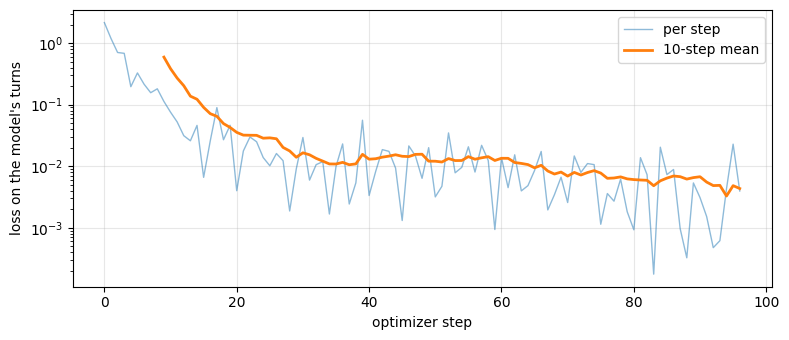

In [14]:
# The training loss. It should fall fast: most of each reply is format (the tool-call JSON, the answer template), and
# what remains is picking the right row and number.
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(8, 3.5))
    plt.plot(losses, lw=1, alpha=0.5, label='per step')
    k = 10
    plt.plot(range(k - 1, len(losses)), [sum(losses[i - k + 1:i + 1]) / k for i in range(k - 1, len(losses))], lw=2, label=f'{k}-step mean')
    plt.xlabel('optimizer step'); plt.ylabel('loss on the model\'s turns'); plt.yscale('log'); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f'{FT}/loss.png', dpi=120); plt.show()
except ImportError:
    print('loss by step:', [round(l, 3) for l in losses])

In [15]:
# The tuned model on the same tasks, then side by side with the base model and the earlier runs found on Drive. Each
# version had different tools and synthetic labs, so compare them on the real-file rows: those questions are the same.
tuned = evaluate(eval_tasks + real_tasks, 'tuned')
earlier = {v: f'{OUT}/{d}/eval_tuned.json' for v, d in [('v1', 'finetune'), ('v2', 'finetune_v2')] if v != VERSION}
results = {'base': results['base'], **{v: json.load(open(p)) for v, p in earlier.items() if os.path.exists(p) and not SMOKE},
           VERSION: tuned}
summary(results)

tuned 1/32 · ✓ · 4 steps · 51 chars · 12 s
tuned 2/32 · ✓ · 4 steps · 59 chars · 24 s
tuned 3/32 · ✓ · 3 steps · 116 chars · 39 s
tuned 4/32 · ✓ · 4 steps · 58 chars · 51 s
tuned 5/32 · ✓ · 2 steps · 67 chars · 59 s
tuned 6/32 · ✓ · 4 steps · 59 chars · 71 s
tuned 7/32 · ✓ · 2 steps · 71 chars · 79 s
tuned 8/32 · ✓ · 3 steps · 118 chars · 94 s
tuned 9/32 · ✓ · 5 steps · 115 chars · 113 s
tuned 10/32 · ✓ · 4 steps · 49 chars · 124 s
tuned 11/32 · ✓ · 4 steps · 65 chars · 135 s
tuned 12/32 · ✓ · 4 steps · 58 chars · 147 s
tuned 13/32 · ✓ · 2 steps · 61 chars · 155 s
tuned 14/32 · ✓ · 3 steps · 118 chars · 170 s
tuned 15/32 · ✓ · 4 steps · 60 chars · 182 s
tuned 16/32 · ✓ · 5 steps · 104 chars · 201 s
tuned 17/32 · ✓ · 2 steps · 56 chars · 208 s
tuned 18/32 · ✓ · 5 steps · 123 chars · 229 s
tuned 19/32 · ✓ · 2 steps · 64 chars · 236 s
tuned 20/32 · ✓ · 4 steps · 55 chars · 250 s
tuned 21/32 · ✗ · 6 steps · 0 chars · 274 s
tuned 22/32 · ✓ · 2 steps · 57 chars · 282 s
tuned 23/32 · ✗ · 6 st

In [16]:
# The question the untuned agent failed in its first run (baseline_trace_qwen3-1.7b.txt). It asks two things at once,
# which no training task did, so this shows whether the habit stretches beyond the templates.
set_root(LAB)
demo = run_agent('In the recall test results, which model copies best when the first copy is far back, '
                 'and how does attn-gqa compare with llama-style?', generate, max_steps=MAX_STEPS)
print('\n══ answer ══\n' + str(demo['answer']))


── step 1 · context 764 tokens ──
<tool_call>
{"name": "list_files", "arguments": {"folder": "."}}
</tool_call>
  → list_files({"folder": "."}) returned 30 characters

── step 2 · context 803 tokens ──
<tool_call>
{"name": "list_files", "arguments": {"folder": "recall"}}
</tool_call>
  → list_files({"folder": "recall"}) returned 703 characters

── step 3 · context 1,108 tokens ──
<tool_call>
{"name": "get_value", "arguments": {"path": "recall/summary.csv", "run": "attn-gqa", "column": "copies"}}
</tool_call>
  → get_value({"path": "recall/summary.csv", "run": "attn-gqa", "column": "copies"}) returned 240 characters

── step 4 · context 1,263 tokens ──
<tool_call>
{"name": "get_value", "arguments": {"path": "recall/summary.csv", "run": "attn-gqa", "column": "copy far %"}}
</tool_call>
  → get_value({"path": "recall/summary.csv", "run": "attn-gqa", "column": "copy far %"}) returned 50 characters

── step 5 · context 1,334 tokens ──
<tool_call>
{"name": "get_value", "arguments": {"path":

In [17]:
# Where the tuned model still fails: its wrong answers next to the gold strings.
for r in tuned:
    if not r['correct']:
        calls = ' → '.join(f"{c['name']}({', '.join(str(v) for v in c['arguments'].values())})" for c in r['trace'])
        print(f"[{r['set']}/{r['kind']}] {r['question']}\n  gold:  {r['gold']}\n  calls: {calls or 'none'}\n"
              f"  got:   {r['answer'][:300]}\n")

[real/compare] In the training results, is attn-swa or gpt2+rmsnorm higher on train tok/s (k)?
  gold:  ['139.0', '187.0']
  calls: list_files(.) → list_files(recall) → get_value(recall/summary.csv, attn-swa, train tok/s (k)) → get_value(recall/summary.csv, attn-swa, train tok/s (k)) → get_value(recall/summary.csv, attn-swa, train tok/s (k)) → get_value(recall/summary.csv, attn-swa, train tok/s (k))
  got:   

[real/lookup] What is gpt2+swiglu's train min in the training results?
  gold:  ['45.9']
  calls: list_files(.) → list_files(recall) → get_value(recall/summary.csv, gpt2+swiglu, train min) → get_value(recall/summary.csv, gpt2+swiglu, train min) → list_files(recall) → get_value(recall/summary.csv, gpt2+swiglu, train min)
  got:   

[real/max] Find the run with the lowest val loss in the training results.
  gold:  ['openai-gpt2', '3.4482']
  calls: list_files(.) → list_files(recall) → sort_table(recall/summary.csv, val loss, False) → list_files(recall) → sort_table(recall/summary.c

## Reading the results
- **Correct %** is the headline. The baseline is low mostly because its answers ramble or stop early, not because it
  misreads; *avg answer chars* shows that.
- **Synthetic vs real.** Synthetic eval labs are new random labs of the training kind. The real tasks are about your
  own tables, which training never saw. A large gap means the model learned the templates, not the habit: v1 scored
  70% synthetic and 0% real. The real-file rows are the number to watch.
- **Read the file %** (read or sorted the right table) separates two failures: never finding the table (a search
  problem) and finding it but answering wrongly (a reading problem).
- **v2 → v3.** Compare on the real-file rows, and against the base model too: the base model also gets the new tool,
  so v3 has to beat the tool alone to show the training helped. In the list of wrong answers, the calls line separates
  the failures: a call into `recall/` for a training question is the folder problem; the right call with a wrong
  answer means it ignored the tool's result; `read_file` on a table means it skipped the tools.
- **v1 → v2.** v2's decoys and recovery traces fixed v1's search problem on synthetic labs, and sort_table fixed most
  maxima, but neither transferred fully to the real folders.
- **The demo question** asks two things at once. Training had only one-part questions, so a tuned model may answer
  the first part only. That is the next thing to add to the training data.
- **What this costs.** A model trained on one narrow task can get worse at others; it may now look for a file even
  when none is needed. Keep the untuned model for general chat, and use the adapter for lab questions.
- To use the adapter in `mini_agent`, set `USE_ADAPTER = True` and `ADAPTER_VERSION` there.